# 03. Feature Engineering & Analytical Datasets — UCI Online Retail II

**Project:** E-Commerce Customer Analytics  
**Objective:** Engineer validated transaction, customer, product, country, and monthly analytical tables from `dataset/processed/cleaned_online_retail.csv` using only verified real attributes—with transparent handling of returns, cancellations, service codes, and missing `Customer ID`s.

> **Accounting & Business Rules Used Throughout:**
> - **Net Realized Revenue / Spending / Quantity:** Combines normal sales (`is_cancelled=False`) and valid `C`-prefixed returns/cancellations (`is_cancelled=True`) so reversed orders do not inflate totals. Gross and returned figures are retained alongside net columns for full auditability.
> - **Order Counts (`TotalOrders` / `Frequency`):** Counts distinct **purchase invoices** (`is_cancelled=False`), while `CancelledOrders` is tracked separately.
> - **Customer Scope:** Uses identified customers (`has_customer_id=True`) without inventing IDs for guest checkouts.
> - **Recency Reference Date:** Defined consistently as **`2011-12-10 00:00:00`** (one day after the final transaction date `2011-12-09`).

Transaction features shape: 1,026,678 rows x 25 columns


,invoice,invoice_date,TotalAmount,Year,Month,MonthName,Quarter,Day,DayOfWeek,DayName,Hour,IsWeekend,InvoiceYearMonth
0,489434,2009-12-01 07:45:00,83.4,2009,12,December,4,1,1,Tuesday,7,False,2009-12
1,489434,2009-12-01 07:45:00,81.0,2009,12,December,4,1,1,Tuesday,7,False,2009-12
2,489434,2009-12-01 07:45:00,81.0,2009,12,December,4,1,1,Tuesday,7,False,2009-12
3,489434,2009-12-01 07:45:00,100.8,2009,12,December,4,1,1,Tuesday,7,False,2009-12
4,489434,2009-12-01 07:45:00,30.0,2009,12,December,4,1,1,Tuesday,7,False,2009-12


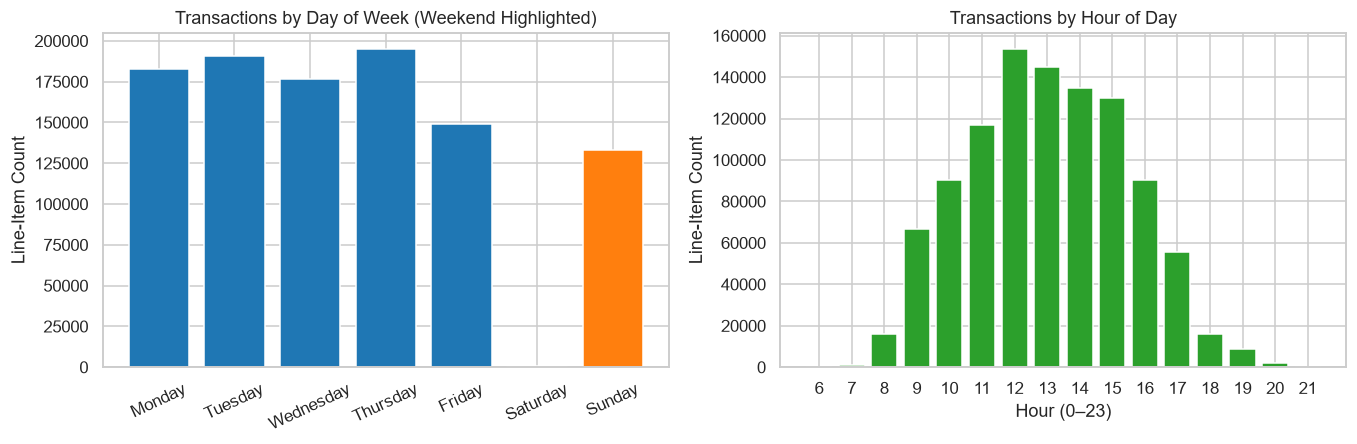

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.engineering import (
    add_transaction_features,
    build_country_analytics,
    build_customer_analytics,
    build_monthly_sales,
    build_product_analytics,
    export_analytical_datasets,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

CLEANED_PATH = PROJECT_ROOT / "dataset" / "processed" / "cleaned_online_retail.csv"
cleaned_df = pd.read_csv(
    CLEANED_PATH,
    dtype={
        "invoice": "string",
        "stock_code": "string",
        "description": "string",
        "customer_id": "Int64",
        "country": "string",
        "transaction_type": "string",
    },
    parse_dates=["invoice_date"],
)

tx_df = add_transaction_features(cleaned_df)
assert float((tx_df["TotalAmount"] - (tx_df["quantity"] * tx_df["price"]).round(4)).abs().max()) == 0.0

tx_new_cols = [
    "invoice", "invoice_date", "TotalAmount", "Year", "Month", "MonthName",
    "Quarter", "Day", "DayOfWeek", "DayName", "Hour", "IsWeekend", "InvoiceYearMonth",
]
print(f"Transaction features shape: {tx_df.shape[0]:,} rows x {tx_df.shape[1]} columns")
display(tx_df[tx_new_cols].head(5))

# Plot transaction volume by DayOfWeek and Hour
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_counts = tx_df["DayName"].value_counts().reindex(day_order, fill_value=0)
day_colors = ["#1f77b4" if d not in ("Saturday", "Sunday") else "#ff7f0e" for d in day_order]
axes[0].bar(day_counts.index, day_counts.values, color=day_colors)
axes[0].set_title("Transactions by Day of Week (Weekend Highlighted)")
axes[0].set_ylabel("Line-Item Count")
axes[0].tick_params(axis="x", rotation=25)

hour_counts = tx_df["Hour"].value_counts().sort_index()
axes[1].bar(hour_counts.index, hour_counts.values, color="#2ca02c")
axes[1].set_title("Transactions by Hour of Day")
axes[1].set_xlabel("Hour (0–23)")
axes[1].set_ylabel("Line-Item Count")
axes[1].set_xticks(hour_counts.index)

plt.tight_layout()
plt.show()

### 1. Transaction-Level Features Analysis
- Enriched all **1,026,678** validated transactions with `TotalAmount`, `Year`, `Month`, `MonthName`, `Quarter`, `Day`, `DayOfWeek` (`0=Monday .. 6=Sunday`), `DayName`, `Hour`, `IsWeekend`, and `InvoiceYearMonth`.
- Verified `TotalAmount == round(quantity * price, 4)` with zero rounding discrepancy across the entire table.
- Interestingly, **zero Saturday transactions** appear in this wholesale-oriented UK e-tailer (`Saturday = 0` rows), while Sunday accounts for regular weekend activity and peak transaction volume concentrates between **10:00 and 15:00** on weekdays.

Recency Reference Date: 2011-12-10 00:00:00
Customer scope breakdown: {'all_identified_customers': 5921, 'purchasing_customers': 5869, 'return_only_customers_excluded': 52}
customer_analytics shape: 5,869 rows x 16 columns
Customers with Net TotalSpending <= 0: 40


,Customer ID,TotalSpending,TotalOrders,TotalQuantity,UniqueProductsPurchased,AverageOrderValue,FirstPurchaseDate,LastPurchaseDate,Recency,Frequency,MonetaryValue,GrossSpending,ReturnedAmount,CancelledOrders,GrossQuantity,ReturnedQuantity
0,18102,570380.61,145,180415,382,3933.66,2009-12-01 09:24:00,2011-12-09 11:50:00,1,145,570380.61,580987.04,-10606.43,8,181645,-1230
1,14646,523342.07,151,364580,961,3465.84,2009-12-02 16:52:00,2011-12-08 12:12:00,2,151,523342.07,528602.52,-5260.45,12,367193,-2613
2,14156,295524.15,150,162239,1445,1970.16,2009-12-01 12:30:00,2011-11-30 10:54:00,10,150,295524.15,312898.33,-17374.18,46,164319,-2080
3,14911,265194.55,394,141496,2548,673.08,2009-12-01 11:41:00,2011-12-08 15:54:00,2,394,265194.55,290857.45,-25662.90,112,147968,-6472
4,17450,231390.55,51,80190,144,4537.07,2010-09-27 16:59:00,2011-12-01 13:29:00,9,51,231390.55,244784.25,-13393.70,10,83914,-3724
5,13694,190020.84,143,184534,896,1328.82,2009-12-04 15:26:00,2011-12-06 09:32:00,4,143,190020.84,195640.69,-5619.85,21,188201,-3667
6,17511,168491.62,60,115449,657,2808.19,2009-12-02 10:52:00,2011-12-07 10:12:00,3,60,168491.62,172132.87,-3641.25,25,117174,-1725
7,12415,143269.29,28,91019,498,5116.76,2010-06-30 08:30:00,2011-11-15 14:22:00,25,28,143269.29,144458.37,-1189.08,5,91447,-428


,TotalSpending,TotalOrders,TotalQuantity,UniqueProductsPurchased,AverageOrderValue,Recency,Frequency,MonetaryValue
count,5869.00,5869.00,5869.00,5869.00,5869.00,5869.00,5869.00,5869.00
mean,2786.77,6.29,1710.94,82.11,347.16,201.24,6.29,2786.77
std,13752.99,12.96,8529.07,116.51,447.90,208.77,12.96,13752.99
min,-10953.50,1.00,-1085.00,1.00,-10953.50,1.00,1.00,-10953.50
25%,331.24,1.00,183.00,19.00,171.15,26.00,1.00,331.24
50%,840.24,3.00,474.00,45.00,270.76,96.00,3.00,840.24
75%,2166.63,7.00,1327.00,103.00,403.71,380.00,7.00,2166.63
max,570380.61,394.00,364580.00,2548.00,11880.84,739.00,394.00,570380.61


Spot-check customers with massive cancelled orders (16446, 12346, 15098):


,Customer ID,TotalSpending,TotalOrders,TotalQuantity,UniqueProductsPurchased,AverageOrderValue,FirstPurchaseDate,LastPurchaseDate,Recency,Frequency,MonetaryValue,GrossSpending,ReturnedAmount,CancelledOrders,GrossQuantity,ReturnedQuantity
3362,15098,649.50,3,60,1,216.50,2011-06-10 15:22:00,2011-06-10 15:33:00,183,3,649.50,39916.50,-39267.0,2,121,-61
5828,16446,2.90,2,2,3,1.45,2011-05-18 09:52:00,2011-12-09 09:15:00,1,2,2.90,168472.50,-168469.6,1,80997,-80995
5855,12346,-147.24,3,9,25,-49.08,2010-03-02 13:08:00,2011-01-18 10:01:00,326,3,-147.24,77352.96,-77500.2,3,74239,-74230


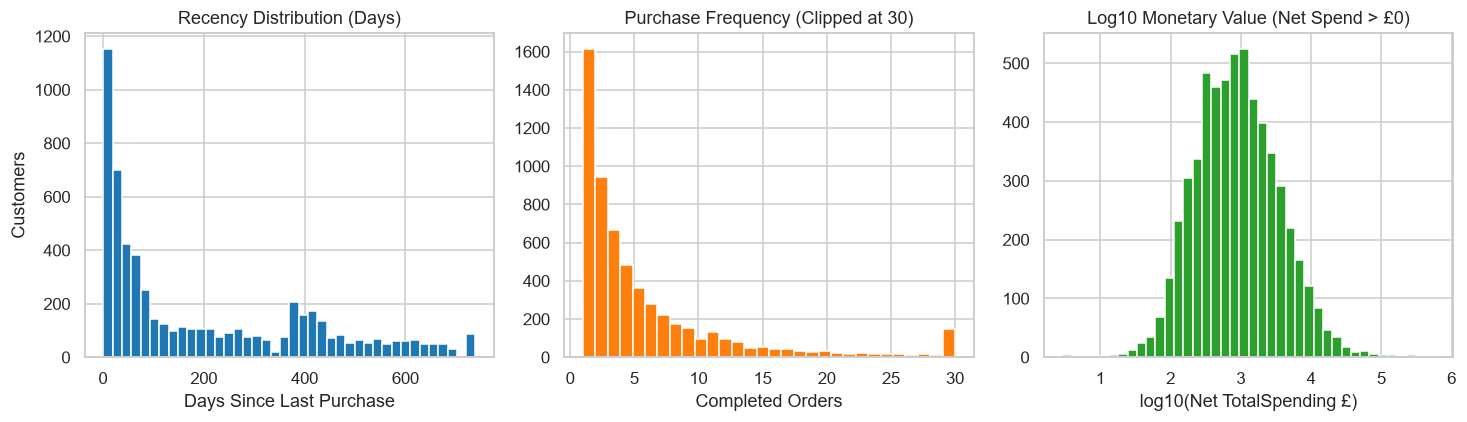

In [2]:
customer_df, reference_date, cust_meta = build_customer_analytics(tx_df)
print(f"Recency Reference Date: {reference_date}")
print(f"Customer scope breakdown: {cust_meta}")
print(f"customer_analytics shape: {customer_df.shape[0]:,} rows x {customer_df.shape[1]} columns")
print(f"Customers with Net TotalSpending <= 0: {int((customer_df['TotalSpending'] <= 0).sum())}")

display(customer_df.head(8))
display(customer_df[["TotalSpending", "TotalOrders", "TotalQuantity", "UniqueProductsPurchased", "AverageOrderValue", "Recency", "Frequency", "MonetaryValue"]].describe().round(2))

# Inspect how netting cancellations corrects giant reversed orders
print("Spot-check customers with massive cancelled orders (16446, 12346, 15098):")
display(customer_df[customer_df["Customer ID"].isin([16446, 12346, 15098])])

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
axes[0].hist(customer_df["Recency"], bins=40, color="#1f77b4", edgecolor="white")
axes[0].set_title("Recency Distribution (Days)")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Customers")

freq_zoom = customer_df["Frequency"].clip(upper=30)
axes[1].hist(freq_zoom, bins=30, color="#ff7f0e", edgecolor="white")
axes[1].set_title("Purchase Frequency (Clipped at 30)")
axes[1].set_xlabel("Completed Orders")

pos_mon = customer_df.loc[customer_df["MonetaryValue"] > 0, "MonetaryValue"]
axes[2].hist(np.log10(pos_mon), bins=40, color="#2ca02c", edgecolor="white")
axes[2].set_title("Log10 Monetary Value (Net Spend > £0)")
axes[2].set_xlabel("log10(Net TotalSpending £)")

plt.tight_layout()
plt.show()

### 2. Customer-Level Dataset & RFM Business Rules Analysis
- **Reference Date (`2011-12-10 00:00:00`):** Set to midnight immediately after the final dataset date (`2011-12-09`), yielding clean integer `Recency` values from **`1` day to `739` days** (median **`96` days**).
- **Customer Coverage (`5,869` purchasing customers):** Out of `5,921` identified customers in `cleaned_online_retail.csv`, `5,869` placed at least one purchase order, while `52` customers only recorded `C`-prefixed returns/cancellations (`-£60,944.33` net) during this window and have no purchase date for `Recency`/`AverageOrderValue`.
- **Why Netting Returns Is Essential:** Notice Customers `16446` (`£168,472.50` gross vs `-£168,469.60` cancelled -> **`£2.90` net**) and `12346` (`£77,352.96` gross vs `-£77,500.20` cancelled -> **`-£147.24` net**). Netting cancellations prevents cancelled orders from creating fake multi-hundred-thousand-pound VIPs. Across all `5,869` customers, `40` have net `TotalSpending <= 0` due to full cancellations or returns against pre-window purchases.

product_analytics shape (is_merchandise=True): 4,746 products x 13 columns
Duplicate StockCodes: 0
Products with Net TotalRevenue <= 0 (return-heavy/prior-period returns): 35

Top 10 Merchandise Products by Net TotalRevenue:


,StockCode,Description,TotalQuantitySold,TotalRevenue,TotalInvoices,UniqueCustomers,AverageSellingPrice,GrossQuantitySold,GrossRevenue,ReturnedQuantity,ReturnedRevenue,SalesInvoices,ReturnInvoices
0,22423,REGENCY CAKESTAND 3 TIER,25028,314045.02,4259,1316,12.4855,26478,330590.32,-1450,-16545.30,3918,341
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,91082,251781.63,5598,1494,2.7573,94719,261168.73,-3637,-9387.10,5464,134
2,85099B,JUMBO BAG RED RETROSPOT,95963,180512.16,4096,978,1.8799,97176,182680.98,-1213,-2168.82,4013,83
3,47566,PARTY BUNTING,27915,147079.73,2697,894,5.2595,28200,148318.28,-285,-1238.55,2674,23
4,84879,ASSORTED COLOUR BIRD ORNAMENT,79571,128550.42,2826,1012,1.6149,80082,129324.49,-511,-774.07,2807,19
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,34494,116298.59,2034,896,3.3565,35084,117760.29,-590,-1461.70,2018,16
6,79321,CHILLI LIGHTS,15696,79905.13,1156,306,5.0843,15841,80540.88,-145,-635.75,1135,21
7,22197,SMALL POPCORN HOLDER,87695,78903.62,2412,601,0.8985,88499,79520.20,-804,-616.58,2322,90
8,22386,JUMBO BAG PINK POLKADOT,38955,75457.64,2270,601,1.9354,39437,76324.62,-482,-866.98,2245,25
9,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,22028,70969.95,762,300,2.2701,31409,71300.40,-9381,-330.45,756,6


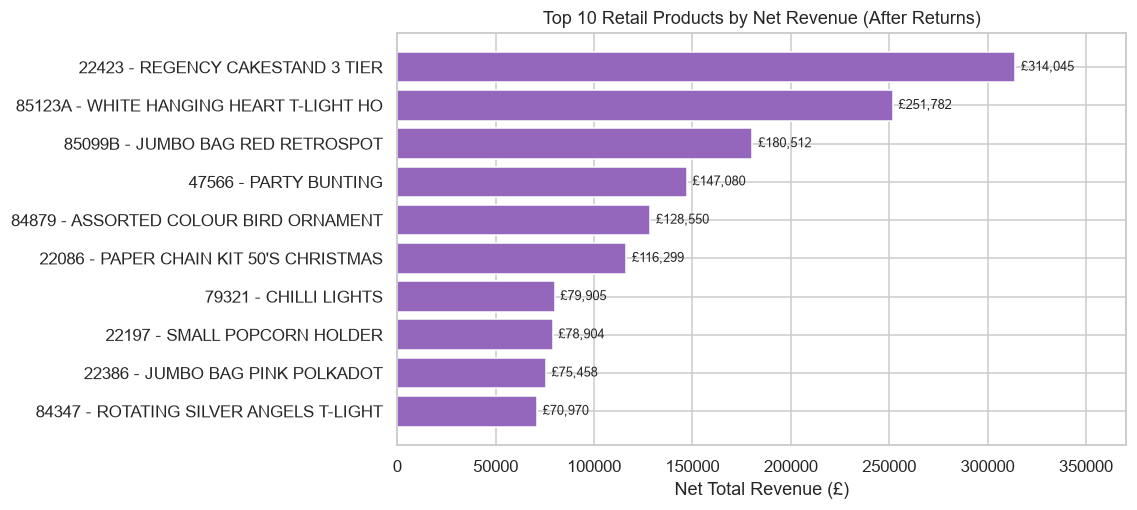

In [3]:
product_df = build_product_analytics(tx_df)
print(f"product_analytics shape (is_merchandise=True): {product_df.shape[0]:,} products x {product_df.shape[1]} columns")
print(f"Duplicate StockCodes: {int(product_df['StockCode'].duplicated().sum())}")
print(f"Products with Net TotalRevenue <= 0 (return-heavy/prior-period returns): {int((product_df['TotalRevenue'] <= 0).sum())}")

print("\nTop 10 Merchandise Products by Net TotalRevenue:")
display(product_df.head(10))

fig, ax = plt.subplots(figsize=(10.5, 4.8))
top10_prod = product_df.head(10).sort_values("TotalRevenue")
labels = [f"{r.StockCode} - {str(r.Description)[:30]}" for r in top10_prod.itertuples()]
bars = ax.barh(labels, top10_prod["TotalRevenue"], color="#9467bd")
ax.set_xlabel("Net Total Revenue (£)")
ax.set_title("Top 10 Retail Products by Net Revenue (After Returns)")
for bar, val in zip(bars, top10_prod["TotalRevenue"]):
    ax.text(val + 3000, bar.get_y() + bar.get_height() / 2, f"£{val:,.0f}", va="center", fontsize=8.5)
ax.set_xlim(0, top10_prod["TotalRevenue"].max() * 1.18)
plt.tight_layout()
plt.show()

### 3. Product-Level Dataset Analysis
- Built across all **4,746 unique merchandise `StockCode`s** (`is_merchandise == True`), excluding the `5,328` non-product service/fee rows (`POST`, `DOT`, `C2`, `D`, `M`, which account for `£336,846.03` net) so shipping and manual ledger fees do not rank as "top products."
- **Returns Handling:** `TotalQuantitySold` and `TotalRevenue` reflect net units and net revenue after `C`-prefixed returns, while `GrossQuantitySold`, `GrossRevenue`, `ReturnedQuantity`, and `ReturnedRevenue` preserve full visibility.
- Each `StockCode` maps deterministically to its most frequent `Description` (**`0` duplicate `StockCode`s**). `AverageSellingPrice` uses quantity-weighted `GrossRevenue / GrossQuantitySold` (falling back to mean unit price for the small group of return-only SKUs).

country_analytics shape: 43 countries x 9 columns


,Country,TotalRevenue,TotalOrders,TotalCustomers,TotalQuantity,AverageOrderValue,GrossRevenue,ReturnedAmount,CancelledOrders
0,United Kingdom,16398388.18,36471,5399,8833666,449.63,17370456.73,-972068.55,7146
1,EIRE,608374.51,612,3,327143,994.08,657128.94,-48754.43,179
2,Netherlands,548349.08,228,22,381214,2405.04,554038.09,-5689.01,20
3,Germany,411904.37,786,107,221797,524.05,424889.47,-12985.10,303
4,France,321676.66,621,94,181570,518.00,350399.36,-28722.70,124
5,Australia,166444.42,95,15,103067,1752.05,169283.46,-2839.04,22
6,Switzerland,99403.06,93,22,52255,1068.85,100685.59,-1282.53,30
7,Spain,90811.94,151,38,44654,601.40,108104.74,-17292.80,33
8,Sweden,87775.52,105,19,87858,835.96,91869.82,-4094.30,24
9,Denmark,64459.59,43,12,234764,1499.06,68580.69,-4121.10,10



monthly_sales shape: 25 months x 11 columns


,Year,Month,MonthName,TotalRevenue,TotalOrders,TotalQuantity,UniqueCustomers,InvoiceYearMonth,GrossRevenue,ReturnedAmount,CancelledOrders
0,2009,12,December,797383.43,1676,415420,1043,2009-12,822355.45,-24972.02,399
1,2010,1,January,615591.20,1065,386765,750,2010-01,642167.18,-26575.98,271
2,2010,2,February,531344.34,1200,374927,805,2010-02,551489.73,-20145.39,238
3,2010,3,March,765490.45,1681,521572,1111,2010-03,830915.26,-65424.81,397
4,2010,4,April,643372.82,1457,360234,996,2010-04,678733.95,-35361.13,294
5,2010,5,May,614830.49,1497,379274,1061,2010-05,657636.26,-42805.77,399
6,2010,6,June,678465.48,1640,391342,1094,2010-06,748776.26,-70310.78,351
7,2010,7,July,618102.86,1525,331713,987,2010-07,648750.27,-30647.41,341
8,2010,8,August,674360.71,1422,465691,964,2010-08,695206.91,-20846.20,270
9,2010,9,September,851467.77,1836,488583,1200,2010-09,921651.99,-70184.22,368


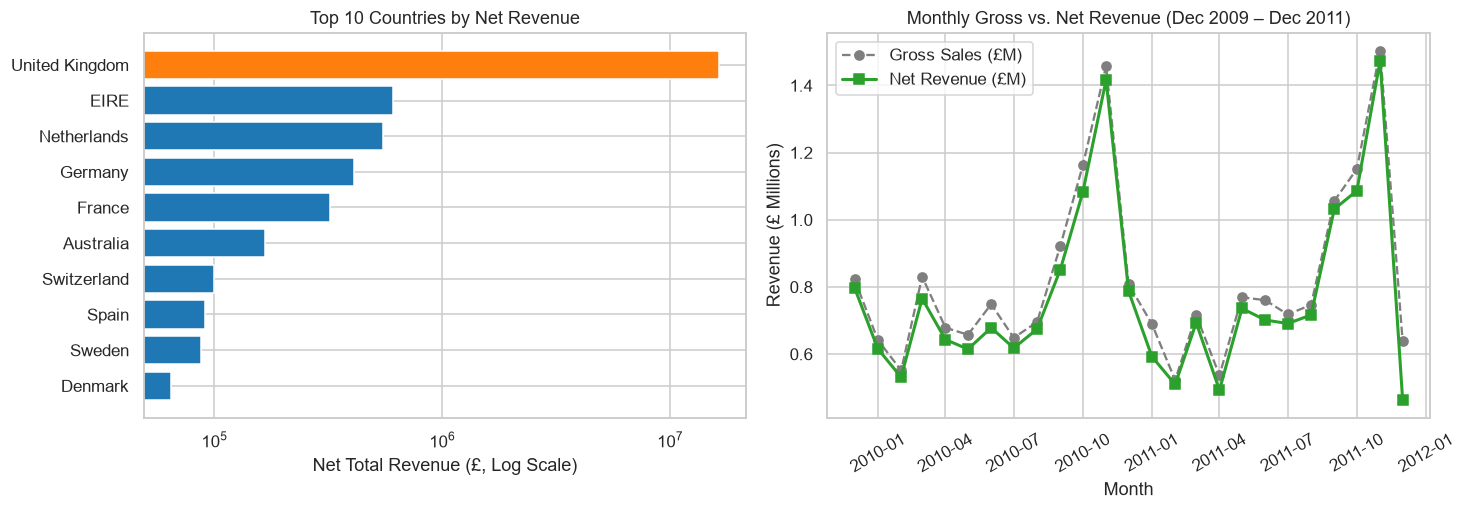

In [4]:
country_df = build_country_analytics(tx_df)
monthly_df = build_monthly_sales(tx_df)

print(f"country_analytics shape: {country_df.shape[0]:,} countries x {country_df.shape[1]} columns")
display(country_df.head(10))

print(f"\nmonthly_sales shape: {monthly_df.shape[0]:,} months x {monthly_df.shape[1]} columns")
display(monthly_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
top10_c = country_df.head(10).sort_values("TotalRevenue")
c_colors = ["#ff7f0e" if c == "United Kingdom" else "#1f77b4" for c in top10_c["Country"]]
axes[0].barh(top10_c["Country"], top10_c["TotalRevenue"], color=c_colors)
axes[0].set_xscale("log")
axes[0].set_xlabel("Net Total Revenue (£, Log Scale)")
axes[0].set_title("Top 10 Countries by Net Revenue")

month_dates = pd.to_datetime(monthly_df["InvoiceYearMonth"] + "-01")
axes[1].plot(month_dates, monthly_df["GrossRevenue"] / 1e6, marker="o", linestyle="--", color="#7f7f7f", label="Gross Sales (£M)")
axes[1].plot(month_dates, monthly_df["TotalRevenue"] / 1e6, marker="s", linewidth=2, color="#2ca02c", label="Net Revenue (£M)")
axes[1].set_title("Monthly Gross vs. Net Revenue (Dec 2009 – Dec 2011)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Revenue (£ Millions)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### 4 & 5. Country-Level & Monthly Sales Analysis
- **Country Analytics (`43` markets):** The **United Kingdom** generates **`£16,398,388.18`** net revenue (`85.12%` of total), followed by **EIRE (`£608,374.51`)**, **Netherlands (`£548,349.08`)**, **Germany (`£411,904.37`)**, and **France (`£321,676.66`)**. Note transparently that `Bermuda` (`£1,253.14`) and `Hong Kong` (`£13,830.50`) consist solely of guest orders (`TotalCustomers = 0`), while `Nigeria` shows `GrossRevenue = £112.57` vs `ReturnedAmount = -£147.05` (`Net TotalRevenue = -£34.48`).
- **Monthly Sales (`25` months):** Clearly reveals strong Q4 holiday surges in **November 2010 (`£1,416,682.20` net)** and **November 2011 (`£1,474,273.68` net)**, while December 2011 (`£463,227.46` net vs `£637,793.33` gross) reflects only the first 9 days of the month plus Customer `16446`'s `-£168,469.60` reversal on Dec 9.

In [5]:
ANALYTICS_DIR = PROJECT_ROOT / "dataset" / "processed" / "analytics"
datasets = {
    "transaction_features": tx_df,
    "customer_analytics": customer_df,
    "product_analytics": product_df,
    "country_analytics": country_df,
    "monthly_sales": monthly_df,
}
saved_paths = export_analytical_datasets(datasets, ANALYTICS_DIR)

for name, path in saved_paths.items():
    print(f"Saved {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size / (1024**2):.2f} MB)")

# Integrity & Reconciliation Validation Checks
assert int(customer_df["Customer ID"].isna().sum()) == 0
assert int(customer_df["Customer ID"].duplicated().sum()) == 0
assert int(product_df["StockCode"].duplicated().sum()) == 0
assert int(country_df["Country"].duplicated().sum()) == 0
assert int(monthly_df["InvoiceYearMonth"].duplicated().sum()) == 0

tx_net_total = float(tx_df["TotalAmount"].sum())
tx_gross_total = float(tx_df.loc[~tx_df["is_cancelled"], "TotalAmount"].sum())
tx_return_total = float(tx_df.loc[tx_df["is_cancelled"], "TotalAmount"].sum())

cust_net_total = float(customer_df["TotalSpending"].sum())
ret_only_cust_total = float(tx_df.loc[tx_df["has_customer_id"] & (~tx_df["customer_id"].isin(customer_df["Customer ID"])), "TotalAmount"].sum())
guest_total = float(tx_df.loc[~tx_df["has_customer_id"], "TotalAmount"].sum())

prod_net_total = float(product_df["TotalRevenue"].sum())
non_merch_total = float(tx_df.loc[~tx_df["is_merchandise"], "TotalAmount"].sum())

ctry_net_total = float(country_df["TotalRevenue"].sum())
monthly_net_total = float(monthly_df["TotalRevenue"].sum())

reconciliation = pd.DataFrame([
    ("Transaction Features (All Valid Cleaned)", round(tx_net_total, 2), 0.00, "Baseline net revenue (Sales £20,434,219.52 + Returns -£1,168,287.81)"),
    ("Country Analytics (All 43 Countries)", round(ctry_net_total, 2), round(ctry_net_total - tx_net_total, 2), "Exact match to transaction baseline"),
    ("Monthly Sales (All 25 Months)", round(monthly_net_total, 2), round(monthly_net_total - tx_net_total, 2), "Penny rounding across 25 monthly groups"),
    ("Product Analytics (4,746 Merchandise SKUs)", round(prod_net_total, 2), round(prod_net_total - tx_net_total, 2), f"Excludes £{non_merch_total:,.2f} from 5,328 non-merchandise service/fee rows (POST/DOT/C2/D/M)"),
    ("Customer Analytics (5,869 Purchasing Customers)", round(cust_net_total, 2), round(cust_net_total - tx_net_total, 2), f"Excludes £{guest_total:,.2f} guest rows (missing Customer ID) and £{ret_only_cust_total:,.2f} from 52 return-only IDs"),
], columns=["Table", "Net Revenue (£)", "Diff vs Baseline (£)", "Exact Reconciliation Explanation"])
display(reconciliation)

Saved dataset\processed\analytics\transaction_features.csv (168.66 MB)
Saved dataset\processed\analytics\customer_analytics.csv (0.59 MB)
Saved dataset\processed\analytics\product_analytics.csv (0.39 MB)
Saved dataset\processed\analytics\country_analytics.csv (0.00 MB)
Saved dataset\processed\analytics\monthly_sales.csv (0.00 MB)


,Table,Net Revenue (£),Diff vs Baseline (£),Exact Reconciliation Explanation
0,Transaction Features (All Valid Cleaned),19265931.71,0.00,"Baseline net revenue (Sales £20,434,219.52 + R..."
1,Country Analytics (All 43 Countries),19265931.71,0.00,Exact match to transaction baseline
2,Monthly Sales (All 25 Months),19265931.70,-0.01,Penny rounding across 25 monthly groups
3,"Product Analytics (4,746 Merchandise SKUs)",18929085.68,-336846.03,"Excludes £336,846.03 from 5,328 non-merchandis..."
4,"Customer Analytics (5,869 Purchasing Customers)",16355566.36,-2910365.35,"Excludes £2,971,309.66 guest rows (missing Cus..."


### Q&A
- **How are the five analytical datasets defined and reconciled?** All five tables derive strictly from the verified `cleaned_online_retail.csv` dataset (`1,026,678` rows, **`£19,265,931.71`** net revenue = **`£20,434,219.52`** sales minus **`£1,168,287.81`** cancellations/returns). `country_analytics.csv` (`£19,265,931.71`) and `monthly_sales.csv` (`£19,265,931.70`, `£0.01` rounding) reconcile to the entire transaction baseline. `product_analytics.csv` (`£18,929,085.68`) isolates real merchandise by excluding `£336,846.03` in non-product fees (`POST`, `DOT`, `C2`, `D`, `M`), and `customer_analytics.csv` (`£16,355,566.36`) covers all `5,869` purchasing customers with valid IDs—explaining the exact gaps from `£2,971,309.66` in guest transactions (missing `Customer ID`) and `-£60,944.33` from `52` return-only customer IDs.
- **How was Recency calculated?** Using a fixed reference date of **`2011-12-10 00:00:00`** (one day after the final observed purchase on `2011-12-09`), yielding `Recency` in days (`1` to `739`, median `96`).

### Data Analysis Key Findings
- **Zero Missing Keys or Duplicates in Analytical Summaries:** `customer_analytics.csv` (`5,869` rows, `0` missing IDs, `0` duplicate IDs), `product_analytics.csv` (`4,746` rows, `0` duplicate `StockCode`s), `country_analytics.csv` (`43` rows), and `monthly_sales.csv` (`25` rows) all passed strict uniqueness and completeness checks.
- **Returns Impact Customer & Product Rankings:** Netting `C`-prefixed cancellations eliminated distorted outlier behavior (such as Customer `16446` dropping from `£168,472.50` gross to `£2.90` net) and revealed `40` customers and `35` merchandise SKUs with net spending/revenue `<= 0`.
- **Temporal & Geographic Signals:** Peak volume occurs between `10:00` and `15:00` on weekdays (`0` Saturday rows), Q4 shows strong seasonal revenue peaks (`£1.42M` in Nov 2010 and `£1.47M` in Nov 2011), and the UK accounts for `85.12%` of net revenue (`£16.40M`).

### Insights or Next Steps
- **Downstream Modeling Caution:** Before applying log transforms or K-Means clustering on `customer_analytics.csv` in RFM/segmentation workflows, decide explicitly how to segment or isolate the `40` customers whose net `MonetaryValue <= 0` (e.g., separate return/churn segment vs positive-value purchasers).
- **Next Step:** Proceed to Exploratory Data Analysis & Business Insights using the five saved CSVs under `dataset/processed/analytics/`.